# 03 · 不足分析与改进探索

检查群体覆盖、交叉支持和人口属性标签敏感性，并探索保持类别总权重的截断重加权。

本文件包含真实统计数据上的分布分析，以及明确设定生成机制的合成模型实验。真实人脸模型的配对重加权结果见02。

In [1]:
# 加载指标与实验函数；本笔记分别进行真实元数据分析和合成机制测试。
from pathlib import Path
import os, sys, json, warnings, time
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd() if (Path.cwd()/"pyproject.toml").exists() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT/"src"))
from experiments import *
warnings.filterwarnings("ignore", category=FutureWarning)
print("项目目录:", ROOT)
print("Python:", sys.version.split()[0], "NumPy:", np.__version__, "Pandas:", pd.__version__)


项目目录: /workspace
Python: 3.12.13 NumPy: 1.26.4 Pandas: 2.1.4


In [2]:
# 用两个小计数表示例区分“组内比例均衡”和“预设群体完整覆盖”。
data=load_data()
audit=counterexamples()
display(pd.DataFrame([audit['single_group']]))
print("两个边缘均 ENS=2，但实际交叉群体只有 2/4；上游组合 richness 返回",audit['upstream_joint_R'])
assert audit['single_group']['IR']==1 and audit['single_group']['coverage']==.5

,R,ENS,D,1/D,1-D,H,SEI,NSD,IR,BP,coverage,H_over_logK,ENS_over_K
0,1,1.0,1.0,1.0,0.0,-0.0,NaN,NaN,1.0,1.0,0.5,-0.0,0.5


两个边缘均 ENS=2，但实际交叉群体只有 2/4；上游组合 richness 返回 4


## 探索一：固定标签空间与交叉群体覆盖

原本只统计观测组，导致单组 IR=1；即使各人口属性的边缘均衡，也可能缺失交叉群体。补充 `coverage=R/K`、`H/log K`、`ENS/K`。这些数依赖预设标签空间，不能把数据集中不可适用的组任意列成“缺失”。这里 K 跟随论文 FairFace 类别，仅作该设定下的技术核验。

覆盖率按实际样本计算；没有样本的群体单独标记。

In [3]:
# K固定为FairFace预设类别数；coverage是实际出现类别数除以K。
coverage=[]
for name,df in data.items():
    for c in COMPONENTS:
        coverage.append({'dataset':name,'component':c,**fixed_universe(df[c].value_counts(),UNIVERSE[c])})
coverage=pd.DataFrame(coverage)
coverage.to_csv(ROOT/'results/tables/coverage.csv',index=False)
display(coverage.pivot(index='dataset',columns='component',values='coverage').round(3))

component,age,gender,race
dataset,,,
adfes,0.222,1.0,0.429
affectnet,1.000,1.0,1.000
caer-s,1.000,1.0,1.000
ck,0.333,1.0,0.857
ck+,0.444,1.0,1.000
expw,1.000,1.0,1.000
fer2013,1.000,1.0,1.000
ferplus,1.000,1.0,1.000
gemep,0.556,1.0,0.143


## 探索二：不确定性与自动标注误差

采用 300 次 multinomial bootstrap 给 V 加区间，并报告有限样本校正 V。此处将数据视作抽样用于**扩展总体推断**；原文将固定数据集视作总体、不做校正，两者问题设定不同，因此与原文回答的问题不同。

限制：V 非负，在零附近有小样本上偏，普通百分位 bootstrap 不保证良好覆盖（JAFFE/race 的原始 V 甚至低于其百分位下界）；因此这里同时报告固定边缘的 300 次随机列联表零假设检验与校正 V，不把区间不含零直接解释为显著关联。置换 p 值仅在相应交换性假设下成立，且本探索未做多重比较校正。

无主体 ID，只能 iid 行级 bootstrap，重复帧可能导致区间过窄。对 FairFace 标签噪声，使用混合扰动展示敏感性，不假设已知真实错误率，也不把扰动当作真实人口属性纠正。

In [4]:
# 在固定随机种子下重采样与置换；标签扰动只用于敏感性分析。
ci=uncertainty(data,reps=300)
display(ci.round(5))
display(pd.read_csv(ROOT/'results/tables/proxy_label_sensitivity.csv'))

,dataset,component,V,V_corrected,ci_low,ci_high,replicates,null_V_mean,permutation_p
0,jaffe,age,NaN,NaN,NaN,NaN,300,NaN,NaN
1,jaffe,race,0.03912,0.00000,0.08005,0.26942,300,0.16843,1.00000
2,jaffe,gender,NaN,NaN,NaN,NaN,300,NaN,NaN
3,ferplus,age,0.10458,0.10341,0.10202,0.11019,300,0.01549,0.00332
4,ferplus,race,0.06768,0.06632,0.06511,0.07272,300,0.01341,0.00332
5,ferplus,gender,0.17096,0.17043,0.15975,0.18214,300,0.01299,0.00332
6,expw,age,0.07215,0.07149,0.06942,0.07579,300,0.00980,0.00332
7,expw,race,0.04104,0.04016,0.03950,0.04423,300,0.00846,0.00332
8,expw,gender,0.15696,0.15673,0.15135,0.16343,300,0.00804,0.00332


,noise_fraction,V
0,0.00,0.170962
1,0.05,0.162414
2,0.10,0.153866
3,0.20,0.136770
4,0.50,0.085481


## 探索三：保持类别分布的截断重加权

设目标分布 $q(g,y)=p(y)/K$，未截断权重 $w_{gy}=q(g,y)/p(g,y)$。为限制方差，先将权重截断到 cap，再按每个 y 重新归一化，**保持各表情类的总权重不变**。截断后的最终最大权重可能高于 cap，所以同时报告实际最大权重。

观察指标：加权 V（越低越独立）、ENS/SEI、有效样本量 $ESS=(\sum w)^2/\sum w^2$。所有 20×3 组件均检查可行性；任一预设群体或群体×类单元缺失时标记为不可行（infeasible）。未截断可以按构造将 V 降为 0，这一代数结果不证明模型公平性，也不证明原始数据已改变。

本节只检查匿名CSV的加权分布。模型训练使用训练集估计权重、固定测试集评价，真实人脸训练对照见02。

检查的数据集×组件: 60
不可行组合: 30


,dataset,component,cap,feasible,missing_cells,V,ENS,SEI,ESS_fraction,max_weight,class_marginal_error
83,ferplus,gender,1,True,0,0.095717,2.0,1.0,0.994083,1.161155,0.0
84,ferplus,gender,2,True,0,0.000000,2.0,1.0,0.970213,1.384232,0.0
85,ferplus,gender,5,True,0,0.000000,2.0,1.0,0.970213,1.384232,0.0
86,ferplus,gender,10,True,0,0.000000,2.0,1.0,0.970213,1.384232,0.0
87,ferplus,gender,0,True,0,0.000000,2.0,1.0,0.970213,1.384232,0.0


,dataset,component,missing_cells
0,adfes,age,42
1,adfes,race,24
22,caer-s,age,12
33,ck+,age,40
34,ck+,race,9
40,ck,age,42
41,ck,race,18
77,ferplus,age,1
88,gemep,age,26
89,gemep,race,36


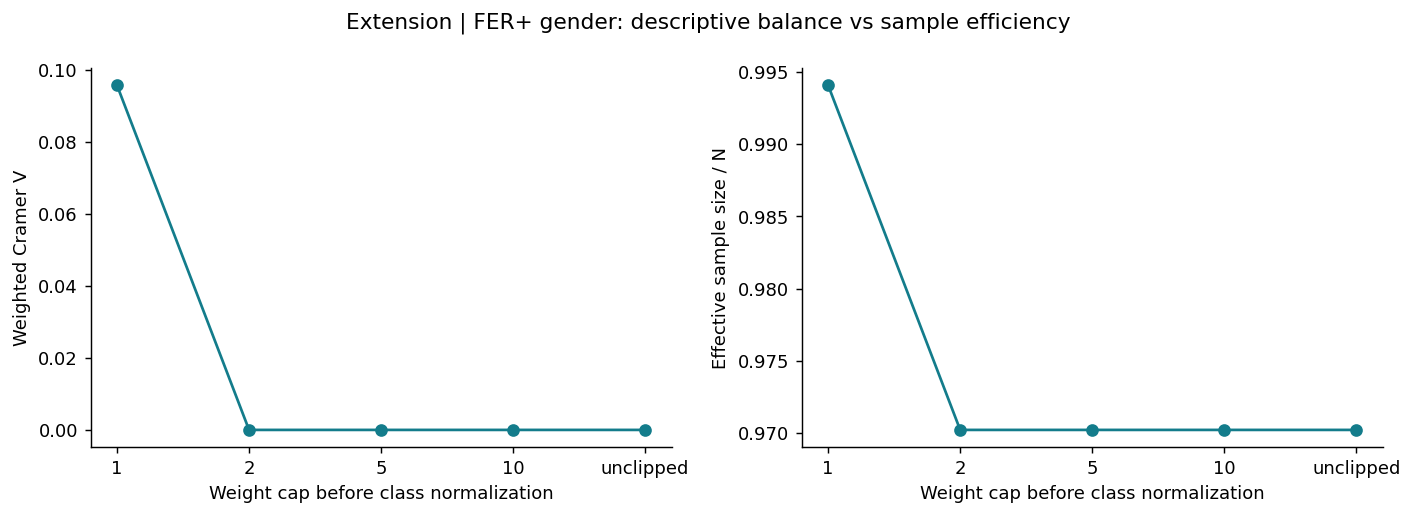

In [5]:
# 先检查群体×表情是否都有样本，再比较不同截断值下的V与有效样本量。
rw=reweighting(data)
print("检查的数据集×组件:",rw[['dataset','component']].drop_duplicates().shape[0])
print("不可行组合:",rw.loc[~rw.feasible,['dataset','component']].shape[0])
display(rw.query("dataset=='ferplus' and component=='gender'"))
display(rw.loc[~rw.feasible,['dataset','component','missing_cells']])
assert rw.loc[rw.feasible,'class_marginal_error'].max()<1e-8
unclipped=rw[rw.feasible & (rw.cap==0)]
assert unclipped.V.max()<1e-10
display(Image(filename=str(ROOT/'results/figures/extension_reweighting.png')))

## 探索四：合成数据中的分布变化与模型表现

本节在指定的结构因果模型（SCM）下进行合成实验，与02中的真实人脸训练分别报告。 使用 20 个随机种子、4000 训练样本、每个测试环境 8000 样本。

数据机制：$Y\sim Bern(0.5)$，$X=2Y-1+\epsilon$，$\epsilon\sim N(0,1.25^2)$。敏感属性 A 通过选择机制与 Y 在训练集 95% 一致；测试包含同分布 95%、独立 50%、反转 5%。在这个 SCM 中 X 不受 A 因果影响，因此配对 `do(A=1-A)` 保持 X/Y/噪声不变。

比较：原始 ERM、仅根据训练表估计的重加权、删除 A 的对照；指标包括准确率、最差 (A,Y) 交叉群体准确率、配对反事实预测翻转率。所有方法共享同一测试样本。

删除 A 在现实中不能保证反事实公平：若 X 是 A 的后代或存在代理变量，必须根据真实因果图重新构造反事实。这里的 SCM 专门允许这个对照，结论仅限合成机制。

accuracy         worst_group_accuracy          \
                           mean     std                 mean     std   
shift       method                                                     
independent Drop A       0.7882  0.0042               0.7744  0.0071   
            ERM          0.5732  0.0143               0.1426  0.0268   
            Reweighted   0.7878  0.0043               0.7665  0.0120   
reversed    Drop A       0.7890  0.0038               0.7613  0.0235   
            ERM          0.1915  0.0234               0.1418  0.0231   
            Reweighted   0.7877  0.0091               0.7554  0.0238   
same        Drop A       0.7894  0.0034               0.7625  0.0182   
            ERM          0.9534  0.0023               0.1299  0.0309   
            Reweighted   0.7897  0.0087               0.7550  0.0187   

                       counterfactual_flip          
                                      mean     std  
shift       method                                  
independent Drop A                  0.0000  0.0000  
            ERM                     0.8440  0.0266  
            Reweighted              0.0118  0.0096  
reversed    Drop A                  0.0000  0.0000  
            ERM                     0.8459  0.0251  
            Reweighted              0.0123  0.0107  
same        Drop A                  0.0000  0.0000  
            ERM                     0.8454  0.0255  
            Reweighted              0.0123  0.0108

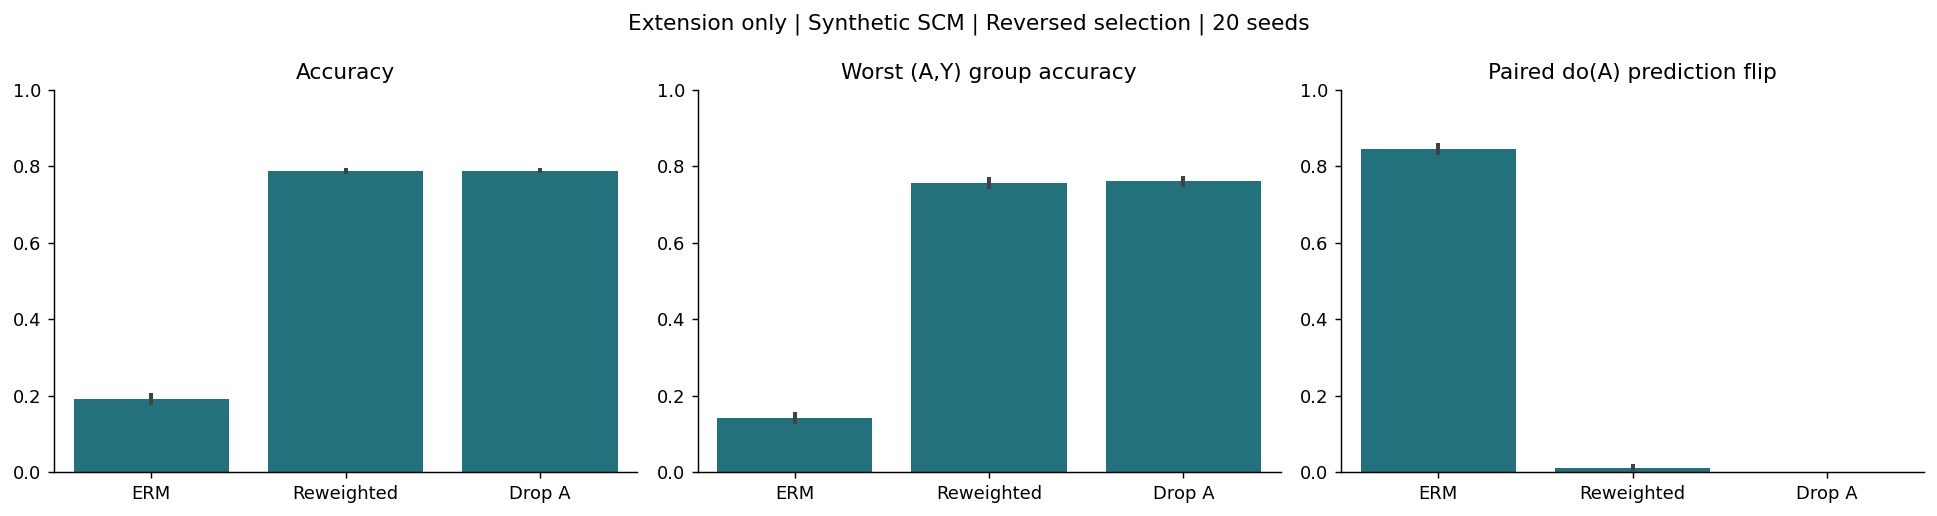

{'n_seeds': 20,
 'mean_accuracy_improvement': 0.59619375,
 'ci_low': 0.5837217409474144,
 'ci_high': 0.6086657590525856}

In [6]:
# 在同一合成机制与测试样本下比较三种方法，再按种子计算配对差。
raw=synthetic_downstream(seeds=20)
summary=raw.groupby(['shift','method'])[['accuracy','worst_group_accuracy','counterfactual_flip']].agg(['mean','std'])
display(summary.round(4))
display(Image(filename=str(ROOT/'results/figures/extension_synthetic.png')))
# 同种子配对差：仅以种子作为独立重复，而不把全部测试行视作 20 倍独立实验。
from scipy.stats import t as student_t
pivot=raw.query("shift=='reversed'").pivot(index='seed',columns='method',values='accuracy')
delta=pivot['Reweighted']-pivot['ERM']
margin=student_t.ppf(.975,len(delta)-1)*delta.std(ddof=1)/np.sqrt(len(delta))
paired={'n_seeds':len(delta),'mean_accuracy_improvement':delta.mean(),'ci_low':delta.mean()-margin,'ci_high':delta.mean()+margin}
(ROOT/'results/tables/synthetic_paired_ci.json').write_text(json.dumps(paired,indent=2))
display(paired)
assert raw.query("method=='Drop A'").counterfactual_flip.max()==0

# 图表和表格已保存在本笔记的输出中，清理重复导出文件。
from result_files import cleanup_results
cleanup_results()

## 改进结果的解释

固定群体空间能揭示遗漏组合；在满足样本支持时，重加权可以调整统计分布。在合成模型中另外检查分布变化的影响，真实人脸模型对照见02。

同时报告有效样本量、准确率与分组召回率，以比较收益和代价。统计关联降低不直接等同于模型或因果公平。